# Telco 客户流失预测（IBM BlastChar 数据集）：四维评估与端到端挽留决策

**数据集**：IBM 电信客户示例数据 `WA_Fn-UseC_-Telco-Customer-Churn.csv`（7,043 名客户 × 21 列）  
**核心任务**：预测客户流失概率 `P(Churn = Yes)`，并结合挽留成本与客户价值制定可落地的精准挽留方案。

### 四维评估体系设计
1. **技术排序能力**：ROC-AUC（主指标）、PR-AUC（正类查准-查全权衡）与 95% Bootstrap 置信区间、配对显著性检验。
2. **概率校准质量**：LogLoss、Brier Score、ECE（预期校准误差）与可靠性曲线（Reliability Diagram），决定概率能否直接用于期望利润计算。
3. **业务落地收益**：预算受限视角（Top-K% Lift 与月费拦截率）、成本敏感期望价值规则（`EV > 0`）、2D 成本敏感性热力图与风险×价值四象限客户分层。
4. **稳健性与可解释性**：5×3 重复分层交叉验证稳定性、子群公平性/校准切片审计、Logistic Odds Ratios 与 TreeSHAP 全局/单客归因。

In [1]:
import os
import warnings
from dataclasses import dataclass
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 4))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

from scipy.optimize import minimize
from scipy.special import logit

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import optuna
import shap

optuna.logging.set_verbosity(optuna.logging.WARNING)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
sns.set_style("whitegrid")
# Re-apply Chinese font after seaborn set_style
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42


@dataclass(frozen=True)
class BusinessConfig:
    contact_cost: float = 5.0
    offer_rate: float = 0.30
    retention_success_rate: float = 0.35
    ltv_horizon_months: float = 6.0


BIZ_CFG = BusinessConfig()


def resolve_data_path() -> Path:
    candidates = [
        Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv"),
        Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"),
        Path("WA_Fn-UseC_-Telco-Customer-Churn.csv"),
        Path("/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    ]
    for p in candidates:
        if p.exists():
            return p.resolve()
    raise FileNotFoundError("未找到 WA_Fn-UseC_-Telco-Customer-Churn.csv，请检查数据路径。")


DATA_PATH = resolve_data_path()
print(f"数据文件路径: {DATA_PATH}")
print(f"业务默认参数: {BIZ_CFG}")

D:\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


数据文件路径: D:\Kaggle\1-Telco 客户流失预测\data\WA_Fn-UseC_-Telco-Customer-Churn.csv
业务默认参数: BusinessConfig(contact_cost=5.0, offer_rate=0.3, retention_success_rate=0.35, ltv_horizon_months=6.0)


## 1. 数据质量体检与基础清洗
对原始数据的深度扫描揭示了 4 个关键事实：
- `Churn = Yes` 占比 **26.54%**（1,869 / 7,043），属于中度不平衡，不可依赖 Accuracy。
- `TotalCharges` 有 **11 条空格字符串 `' '`**，100% 对应 `tenure == 0` 且 `Churn == No` 的新入网客户；应转为数值并填充 `0.0`，严禁均值填充。
- 存在 **18 组特征向量完全相同但 `Churn` 标签相反**的记录，代表可观测特征之外的固有随机噪声。
- `PhoneService=No` 与 `MultipleLines='No phone service'`、`InternetService=No` 与 6 项增值服务的 `'No internet service'` 存在 100% 结构性共线性。

In [2]:
ADDON_COLS = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
SECURITY_SUPPORT_COLS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
STREAMING_COLS = ["StreamingTV", "StreamingMovies"]

raw_df = pd.read_csv(DATA_PATH)

# 数据质量体检
tc_blank_mask = raw_df["TotalCharges"].astype(str).str.strip() == ""
feat_with_y = [c for c in raw_df.columns if c != "customerID"]
feat_only = [c for c in raw_df.columns if c not in ("customerID", "Churn")]
conflict_groups = int((raw_df.groupby(feat_only, dropna=False)["Churn"].nunique() > 1).sum())

audit_summary = pd.Series({
    "总行数": raw_df.shape[0],
    "总列数": raw_df.shape[1],
    "唯一 customerID": raw_df["customerID"].nunique(),
    "流失客户数 (Yes)": int((raw_df["Churn"] == "Yes").sum()),
    "流失率": f"{(raw_df['Churn'] == 'Yes').mean()*100:.2f}%",
    "TotalCharges 空格行数": int(tc_blank_mask.sum()),
    "空格行是否全部 tenure==0": bool((raw_df.loc[tc_blank_mask, "tenure"] == 0).all()),
    "完全重复记录数(去ID)": int(raw_df.duplicated(subset=feat_with_y).sum()),
    "特征相同但标签冲突组数": conflict_groups,
})
display(audit_summary.to_frame("审计结果"))


def clean_base_data(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["TotalCharges"] = pd.to_numeric(out["TotalCharges"].astype(str).str.strip(), errors="coerce").fillna(0.0)
    out["tenure"] = pd.to_numeric(out["tenure"], errors="raise").astype(int)
    out["MonthlyCharges"] = pd.to_numeric(out["MonthlyCharges"], errors="raise").astype(float)
    out["SeniorCitizen"] = pd.to_numeric(out["SeniorCitizen"], errors="raise").astype(int)
    out["Churn"] = out["Churn"].astype(str).map({"Yes": 1, "No": 0}).astype(int)
    return out


clean_df = clean_base_data(raw_df)
clean_df.head(3)

,审计结果
总行数,7043
总列数,21
唯一 customerID,7043
流失客户数 (Yes),1869
流失率,26.54%
TotalCharges 空格行数,11
空格行是否全部 tenure==0,True
完全重复记录数(去ID),22
特征相同但标签冲突组数,18


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


## 2. 探索性数据分析（EDA）与关键流失驱动洞察

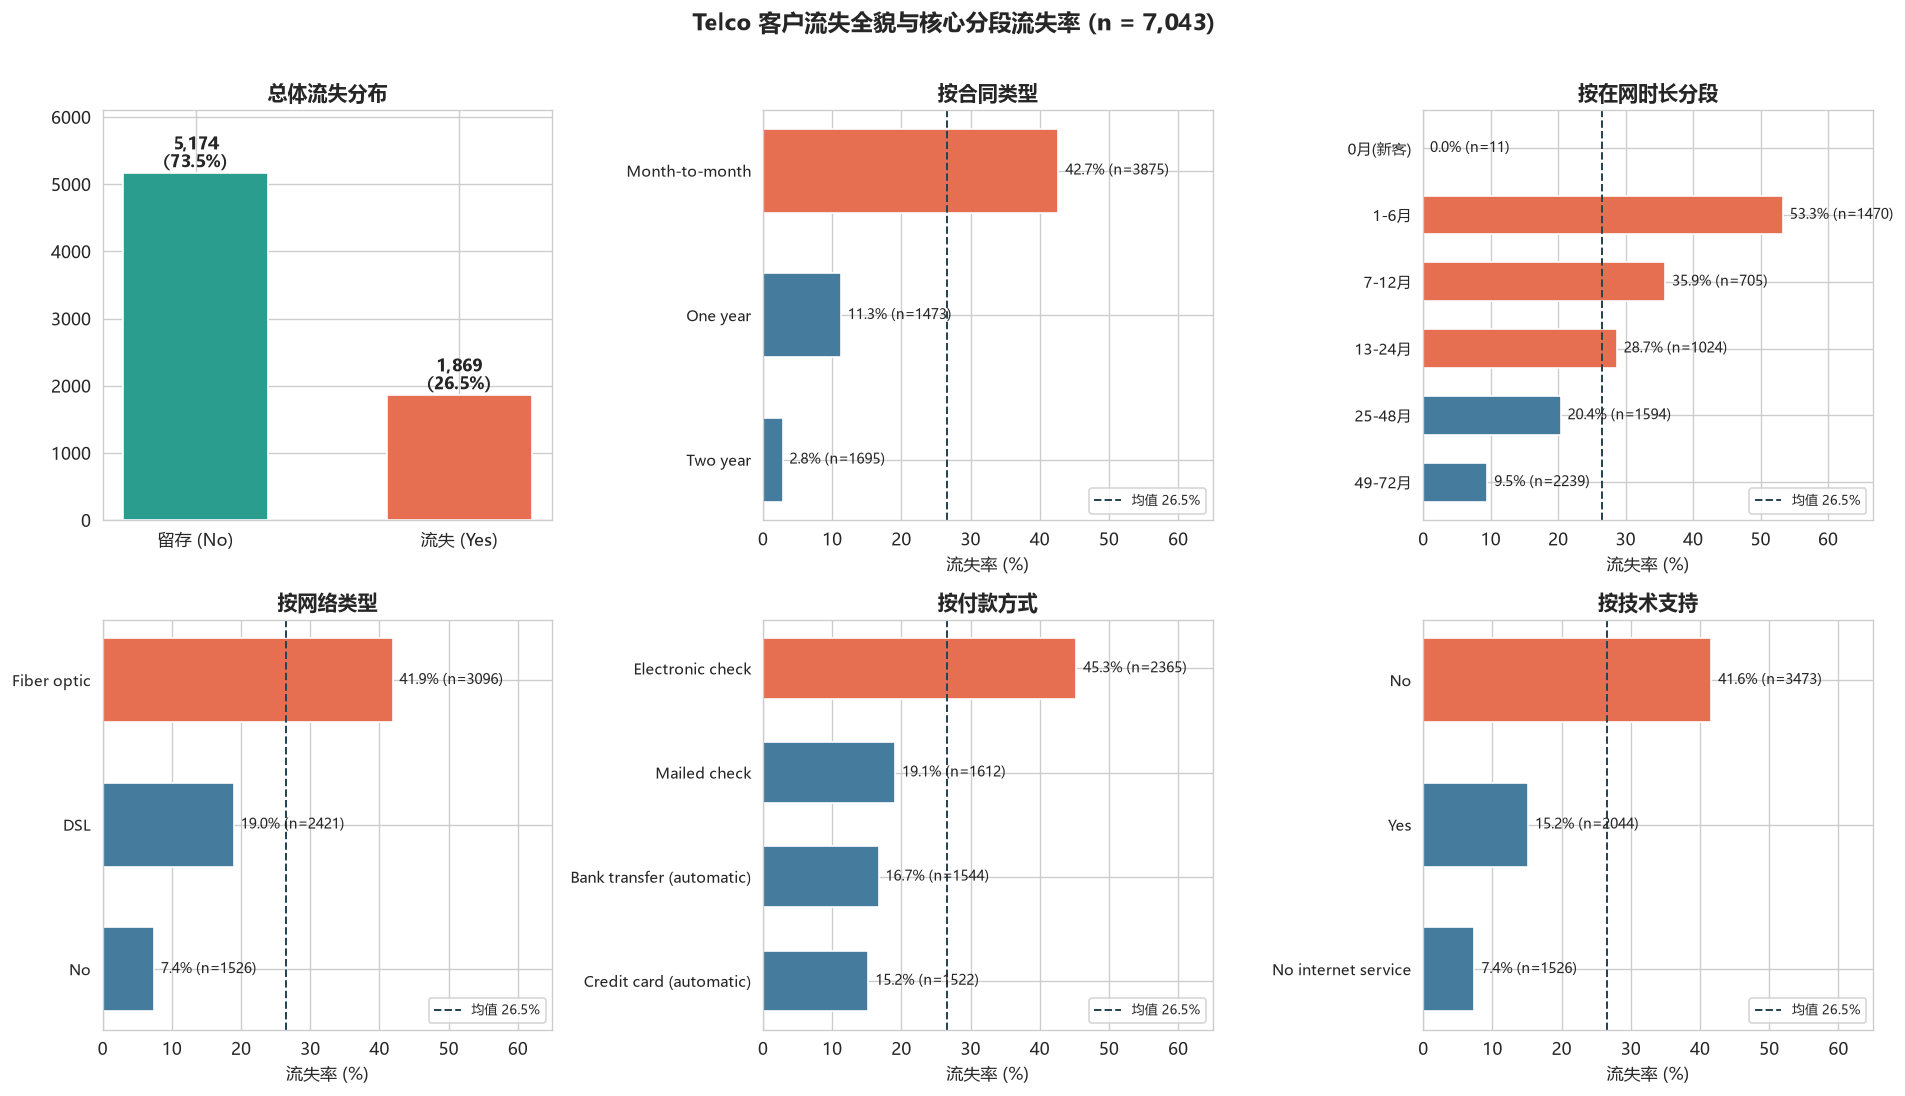

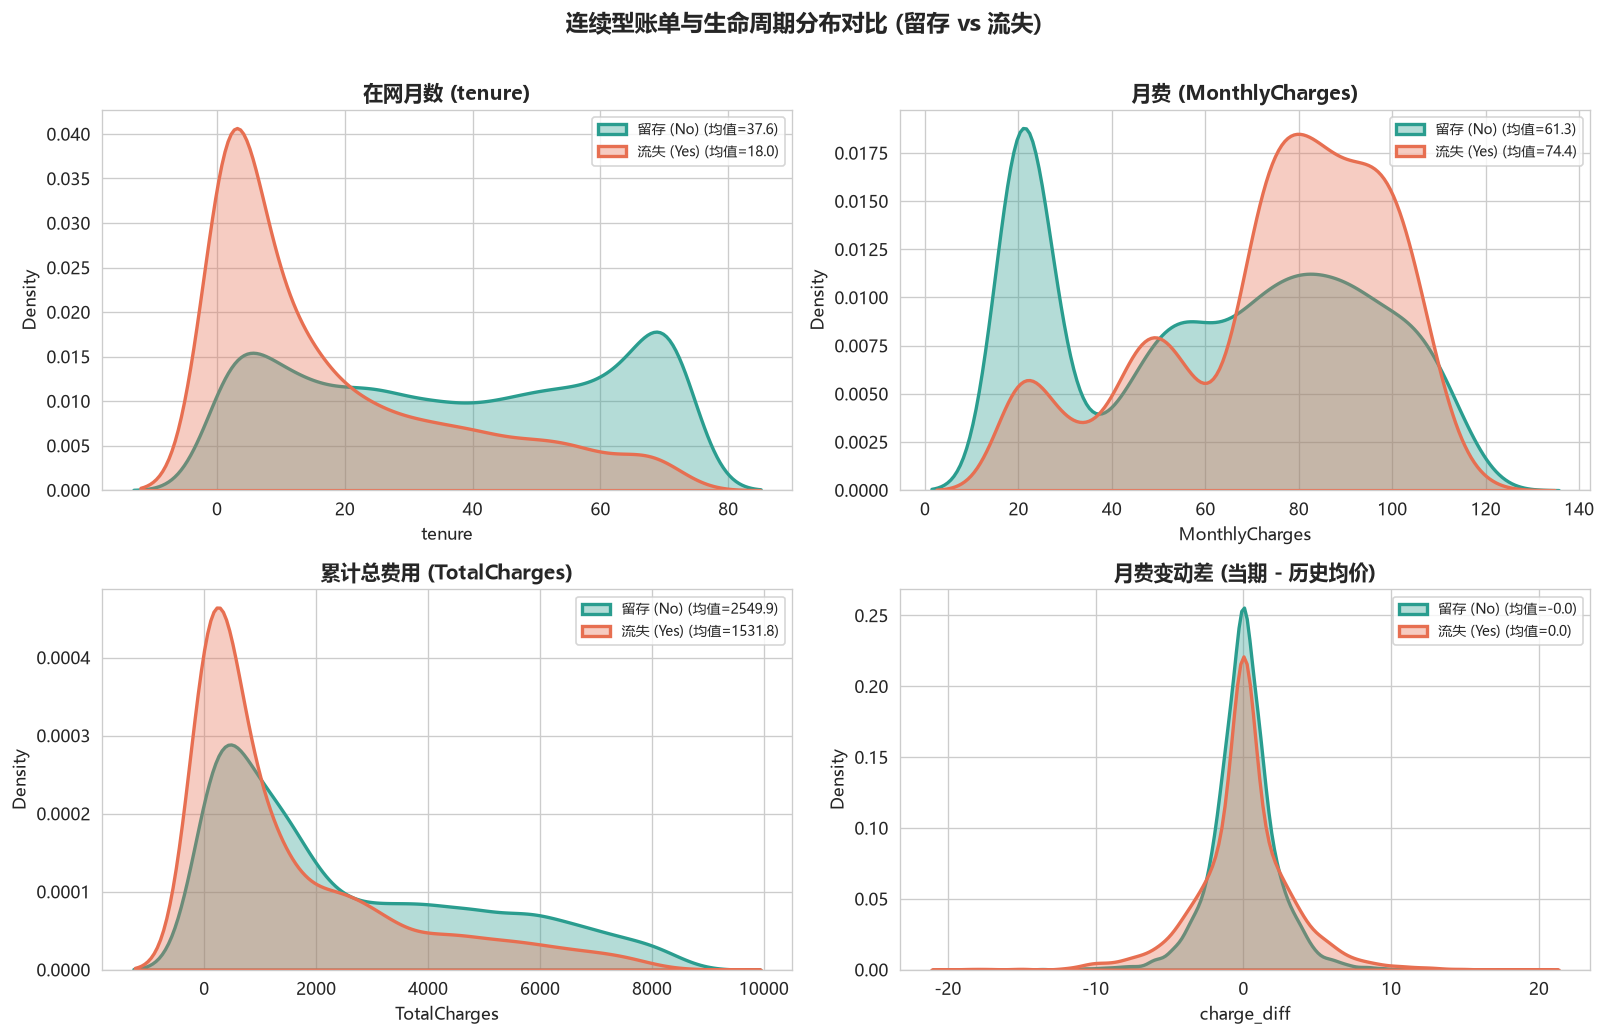

In [3]:
df_eda = clean_df.copy()
df_eda["tenure_group"] = pd.cut(
    df_eda["tenure"],
    bins=[-1, 0, 6, 12, 24, 48, 1000],
    labels=["0月(新客)", "1-6月", "7-12月", "13-24月", "25-48月", "49-72月"],
).astype(str)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Telco 客户流失全貌与核心分段流失率 (n = 7,043)", fontsize=14, fontweight="bold", y=1.01)

ax = axes[0, 0]
cnts = df_eda["Churn"].value_counts().reindex([0, 1])
bars = ax.bar(["留存 (No)", "流失 (Yes)"], cnts.values, color=["#2A9D8F", "#E76F51"], width=0.55)
for b, c in zip(bars, cnts.values):
    ax.text(b.get_x() + b.get_width()/2, c + 80, f"{c:,}\n({c/len(df_eda)*100:.1f}%)", ha="center", fontweight="bold")
ax.set_ylim(0, max(cnts.values) * 1.18)
ax.set_title("总体流失分布", fontweight="bold")

overall = df_eda["Churn"].mean() * 100
panels = [
    (axes[0, 1], "Contract", "按合同类型"),
    (axes[0, 2], "tenure_group", "按在网时长分段"),
    (axes[1, 0], "InternetService", "按网络类型"),
    (axes[1, 1], "PaymentMethod", "按付款方式"),
    (axes[1, 2], "TechSupport", "按技术支持"),
]
orders = {
    "tenure_group": ["0月(新客)", "1-6月", "7-12月", "13-24月", "25-48月", "49-72月"],
    "Contract": ["Month-to-month", "One year", "Two year"],
}
for ax, col, title in panels:
    grp = df_eda.groupby(col)["Churn"].agg(["count", "mean"]).reset_index()
    grp["rate"] = grp["mean"] * 100
    if col in orders:
        grp[col] = pd.Categorical(grp[col], categories=orders[col], ordered=True)
        grp = grp.sort_values(col)
    else:
        grp = grp.sort_values("rate", ascending=False)
    yp = np.arange(len(grp))
    ax.barh(yp, grp["rate"], color=["#E76F51" if r >= overall else "#457B9D" for r in grp["rate"]], height=0.58)
    ax.axvline(overall, color="#264653", linestyle="--", lw=1.2, label=f"均值 {overall:.1f}%")
    ax.set_yticks(yp)
    ax.set_yticklabels(grp[col].astype(str), fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, max(grp["rate"].max() * 1.25, 65))
    for y_i, (_, r) in zip(yp, grp.iterrows()):
        ax.text(r["rate"] + 1.0, y_i, f"{r['rate']:.1f}% (n={int(r['count'])})", va="center", fontsize=8.5)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("流失率 (%)")
    ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

# 连续型特征分布对比
avg_m = np.where(df_eda["tenure"] > 0, df_eda["TotalCharges"] / np.maximum(df_eda["tenure"], 1), df_eda["MonthlyCharges"])
df_eda["charge_diff"] = df_eda["MonthlyCharges"] - avg_m
df_eda["ChurnLabel"] = df_eda["Churn"].map({0: "留存 (No)", 1: "流失 (Yes)"})

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.5))
fig.suptitle("连续型账单与生命周期分布对比 (留存 vs 流失)", fontsize=14, fontweight="bold", y=1.01)
for ax, (col, title) in zip(
    axes.ravel(),
    [
        ("tenure", "在网月数 (tenure)"),
        ("MonthlyCharges", "月费 (MonthlyCharges)"),
        ("TotalCharges", "累计总费用 (TotalCharges)"),
        ("charge_diff", "月费变动差 (当期 - 历史均价)"),
    ],
):
    for lbl, c in [("留存 (No)", "#2A9D8F"), ("流失 (Yes)", "#E76F51")]:
        sub = df_eda.loc[df_eda["ChurnLabel"] == lbl, col]
        sns.kdeplot(sub, ax=ax, fill=True, alpha=0.35, color=c, lw=2, label=f"{lbl} (均值={sub.mean():.1f})")
    ax.set_title(title, fontweight="bold")
    ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

## 3. 组合分层切分与防数据泄露架构
由于全量数据中“两年付且流失（`Two year + Churn=Yes`）”的客户仅 **48 人**，若仅按 `Churn` 分层容易引起稀缺高价值群体在测试集或折间比例抖动。因此我们按 **`Churn × Contract`** 6 组合分层切分 **80% 开发集（5,634 人）** 与 **20% 锁仓测试集（1,409 人）**，后续所有特征消融、调参、概率校准、融合权重与业务阈值均只在开发集 5-Fold CV 上完成。

In [4]:
strata = clean_df["Churn"].astype(str) + "_" + clean_df["Contract"].astype(str)
feature_cols = [c for c in clean_df.columns if c not in ("customerID", "Churn")]

tr_idx, te_idx = train_test_split(
    np.arange(len(clean_df)), test_size=0.20, random_state=RANDOM_STATE, stratify=strata
)
X_train = clean_df.iloc[tr_idx][feature_cols].reset_index(drop=True)
X_test = clean_df.iloc[te_idx][feature_cols].reset_index(drop=True)
y_train = clean_df.iloc[tr_idx]["Churn"].to_numpy(dtype=int)
y_test = clean_df.iloc[te_idx]["Churn"].to_numpy(dtype=int)
strata_train = strata.iloc[tr_idx].reset_index(drop=True)
ids_test = clean_df.iloc[te_idx]["customerID"].reset_index(drop=True)

cv_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, strata_train))

split_check = pd.DataFrame({
    "开发集比例": strata.iloc[tr_idx].value_counts(normalize=True).sort_index(),
    "测试集比例": strata.iloc[te_idx].value_counts(normalize=True).sort_index(),
    "测试集人数": strata.iloc[te_idx].value_counts().sort_index(),
})
print(f"X_train: {X_train.shape} (流失率 {y_train.mean()*100:.2f}%), X_test: {X_test.shape} (流失率 {y_test.mean()*100:.2f}%)")
display(split_check)

X_train: (5634, 19) (流失率 26.54%), X_test: (1409, 19) (流失率 26.54%)


,开发集比例,测试集比例,测试集人数
0_Month-to-month,0.315229,0.315117,444
0_One year,0.185659,0.185238,261
0_Two year,0.233759,0.234209,330
1_Month-to-month,0.235002,0.234918,331
1_One year,0.023607,0.023421,33
1_Two year,0.006745,0.007097,10


## 4. 无泄露特征工程与消融实验（Raw vs +Domain vs +Interaction）

In [5]:
class TelcoFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, collapse_redundant=True, add_domain_features=True, add_interaction_features=True):
        self.collapse_redundant = collapse_redundant
        self.add_domain_features = add_domain_features
        self.add_interaction_features = add_interaction_features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()
        for col in df.select_dtypes(include=["object", "string", "category"]).columns:
            df[col] = df[col].astype(str)
        if self.collapse_redundant:
            for col in ADDON_COLS:
                df[col] = df[col].replace({"No internet service": "No"})
            df["MultipleLines"] = df["MultipleLines"].replace({"No phone service": "No"})

        tenure = pd.to_numeric(df["tenure"]).astype(float)
        monthly = pd.to_numeric(df["MonthlyCharges"]).astype(float)
        total = pd.to_numeric(df["TotalCharges"]).astype(float)

        addon_yes = sum((df[c] == "Yes").to_numpy(dtype=float) for c in ADDON_COLS)
        sec_yes = sum((df[c] == "Yes").to_numpy(dtype=float) for c in SECURITY_SUPPORT_COLS)
        stream_yes = sum((df[c] == "Yes").to_numpy(dtype=float) for c in STREAMING_COLS)
        contract_m = df["Contract"].map({"Month-to-month": 1.0, "One year": 12.0, "Two year": 24.0}).fillna(1.0).to_numpy(dtype=float)

        if self.add_domain_features:
            df["is_new_customer"] = (tenure == 0).astype(int)
            avg_m = np.where(tenure > 0, total / np.maximum(tenure, 1.0), monthly)
            df["avg_monthly_charge"] = avg_m
            df["charge_diff"] = monthly - avg_m
            df["charge_ratio"] = monthly / np.maximum(avg_m, 1.0)
            df["log_tenure"] = np.log1p(tenure)
            df["log_total_charges"] = np.log1p(total)
            df["tenure_bucket"] = pd.cut(
                tenure, bins=[-1, 0, 6, 12, 24, 48, 1000],
                labels=["0m", "1-6m", "7-12m", "13-24m", "25-48m", "49-72m"],
            ).astype(str)
            df["total_addons"] = addon_yes
            df["security_support_count"] = sec_yes
            df["streaming_count"] = stream_yes
            df["has_auto_pay"] = df["PaymentMethod"].str.contains("automatic", case=False, regex=False).astype(int)
            df["is_electronic_check"] = (df["PaymentMethod"] == "Electronic check").astype(int)
            df["has_fiber"] = (df["InternetService"] == "Fiber optic").astype(int)
            df["charge_per_service"] = monthly / (1.0 + addon_yes + (df["PhoneService"] == "Yes").to_numpy(float) + (df["InternetService"] != "No").to_numpy(float))
            df["is_single_no_dep"] = ((df["Partner"] == "No") & (df["Dependents"] == "No")).astype(int)
            df["contract_months"] = contract_m

        if self.add_interaction_features:
            df["contract_x_internet"] = df["Contract"] + "__" + df["InternetService"]
            df["payment_x_paperless"] = df["PaymentMethod"] + "__" + df["PaperlessBilling"]
            df["fiber_no_support"] = ((df["InternetService"] == "Fiber optic") & (df["TechSupport"] != "Yes")).astype(int)
            df["mtm_echeck"] = ((df["Contract"] == "Month-to-month") & (df["PaymentMethod"] == "Electronic check")).astype(int)
            df["tenure_to_contract_ratio"] = tenure / contract_m
            df["monthly_x_mtm"] = monthly * (df["Contract"] == "Month-to-month").to_numpy(float)
            df["no_security_bundle"] = ((df["InternetService"] != "No") & (sec_yes == 0)).astype(int)
        return df


class TelcoTabularPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self, collapse_redundant=True, add_domain_features=True, add_interaction_features=True, scale_numeric=True):
        self.collapse_redundant = collapse_redundant
        self.add_domain_features = add_domain_features
        self.add_interaction_features = add_interaction_features
        self.scale_numeric = scale_numeric

    def fit(self, X, y=None):
        self.engineer_ = TelcoFeatureEngineer(
            self.collapse_redundant, self.add_domain_features, self.add_interaction_features
        )
        X_eng = self.engineer_.fit_transform(X, y)
        num_cols = X_eng.select_dtypes(include=[np.number]).columns.tolist()
        cat_cols = X_eng.select_dtypes(include=["object", "string", "category"]).columns.tolist()
        self.ct_ = ColumnTransformer(
            [
                ("num", StandardScaler() if self.scale_numeric else "passthrough", num_cols),
                ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
            ],
            remainder="drop",
            verbose_feature_names_out=False,
        )
        self.ct_.fit(X_eng, y)
        self.feature_names_out_ = [
            str(n).replace("[", "_").replace("]", "_").replace("<", "lt").replace(">", "gt").replace(" ", "_")
            for n in self.ct_.get_feature_names_out()
        ]
        return self

    def transform(self, X):
        arr = self.ct_.transform(self.engineer_.transform(X))
        return pd.DataFrame(arr, columns=self.feature_names_out_, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_out_, dtype=object)


def compute_ece(y_true, y_prob, n_bins=10):
    yt = np.asarray(y_true, float)
    yp = np.clip(np.asarray(y_prob, float), 1e-7, 1 - 1e-7)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (yp >= bins[i]) & (yp <= bins[i + 1] if i == n_bins - 1 else yp < bins[i + 1])
        if mask.sum() > 0:
            ece += (mask.sum() / len(yt)) * abs(yt[mask].mean() - yp[mask].mean())
    return float(ece)


def calc_metrics(y_true, y_prob):
    yp = np.clip(np.asarray(y_prob, float), 1e-7, 1 - 1e-7)
    return {
        "roc_auc": float(roc_auc_score(y_true, yp)),
        "pr_auc": float(average_precision_score(y_true, yp)),
        "log_loss": float(log_loss(y_true, yp)),
        "brier": float(brier_score_loss(y_true, yp)),
        "ece": compute_ece(y_true, yp),
    }


def eval_cv(pipe_factory, X, y, splits, fit_folds=False):
    oof = np.zeros(len(X), dtype=float)
    f_metrics, pipes = [], []
    for tr, va in splits:
        p = pipe_factory()
        p.fit(X.iloc[tr], y[tr])
        prob = p.predict_proba(X.iloc[va])[:, 1]
        oof[va] = prob
        f_metrics.append(calc_metrics(y[va], prob))
        if fit_folds:
            pipes.append(p)
    fdf = pd.DataFrame(f_metrics)
    return {
        "oof": oof,
        "roc_auc_mean": fdf["roc_auc"].mean(),
        "roc_auc_std": fdf["roc_auc"].std(ddof=1),
        "pr_auc_mean": fdf["pr_auc"].mean(),
        "log_loss_mean": fdf["log_loss"].mean(),
        "brier_mean": fdf["brier"].mean(),
        "oof_metrics": calc_metrics(y, oof),
        "pipes": pipes,
    }


FEATURE_CONFIGS = {
    "Raw": dict(collapse_redundant=False, add_domain_features=False, add_interaction_features=False),
    "+Domain": dict(collapse_redundant=True, add_domain_features=True, add_interaction_features=False),
    "+Domain+Interaction": dict(collapse_redundant=True, add_domain_features=True, add_interaction_features=True),
}

def make_pipe(clf, fc, scale=True):
    return Pipeline([("prep", TelcoTabularPreprocessor(**fc, scale_numeric=scale)), ("clf", clf)])

ablation_rows = []
chosen_feats = {}
for m_name, clf_fn, scale_num in [
    ("LogisticRegression", lambda: LogisticRegression(C=1.0, max_iter=1500, random_state=RANDOM_STATE), True),
    ("LightGBM", lambda: lgb.LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=4, verbose=-1), False),
]:
    best_sc = (-1.0, 0.0)
    for f_name, fc in FEATURE_CONFIGS.items():
        res = eval_cv(lambda c=clf_fn, f=fc, s=scale_num: make_pipe(c(), f, s), X_train, y_train, cv_splits)
        ablation_rows.append({
            "模型": m_name, "特征集合": f_name,
            "CV_ROC_AUC": res["roc_auc_mean"], "CV_AUC_Std": res["roc_auc_std"],
            "CV_PR_AUC": res["pr_auc_mean"], "CV_LogLoss": res["log_loss_mean"],
        })
        sc = (res["roc_auc_mean"], -res["log_loss_mean"])
        if sc > best_sc:
            best_sc = sc
            chosen_feats[m_name] = (f_name, fc)

ablation_df = pd.DataFrame(ablation_rows)
lr_feat_name, lr_feat_cfg = chosen_feats["LogisticRegression"]
tree_feat_name, tree_feat_cfg = chosen_feats["LightGBM"]
print(f"最优特征配置 -> LR: {lr_feat_name}, Tree: {tree_feat_name}")
display(ablation_df.round(4))

最优特征配置 -> LR: +Domain+Interaction, Tree: Raw


,模型,特征集合,CV_ROC_AUC,CV_AUC_Std,CV_PR_AUC,CV_LogLoss
0,LogisticRegression,Raw,0.8494,0.0094,0.6632,0.4126
1,LogisticRegression,+Domain,0.8537,0.0111,0.6831,0.4059
2,LogisticRegression,+Domain+Interaction,0.8537,0.0115,0.6822,0.4059
3,LightGBM,Raw,0.8510,0.0149,0.6752,0.4100
4,LightGBM,+Domain,0.8492,0.0142,0.6712,0.4120
5,LightGBM,+Domain+Interaction,0.8498,0.0154,0.6715,0.4115


## 5. 类别不平衡策略与概率校准影响对比

In [6]:
def individual_ev_profit(y_true, y_prob, charges, cfg: BusinessConfig):
    ltv = charges * cfg.ltv_horizon_months
    cost = cfg.contact_cost + cfg.offer_rate * charges
    ev = y_prob * cfg.retention_success_rate * ltv - cost
    mask = ev > 0
    saved = float((y_true[mask] * cfg.retention_success_rate * ltv[mask]).sum())
    tot_cost = float(cost[mask].sum())
    return saved - tot_cost, float(mask.mean())

monthly_train = X_train["MonthlyCharges"].to_numpy(float)
imb_rows = []
for m_name, fc, scale_num, clf_fn in [
    ("LogisticRegression", lr_feat_cfg, True, lambda cw=None: LogisticRegression(C=1.0, max_iter=1500, class_weight=cw, random_state=RANDOM_STATE)),
    ("LightGBM", tree_feat_cfg, False, lambda cw=None: lgb.LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, class_weight=cw, random_state=RANDOM_STATE, n_jobs=4, verbose=-1)),
]:
    strategies = {
        "Raw (原始分布)": lambda: make_pipe(clf_fn(None), fc, scale_num),
        "class_weight='balanced'": lambda: make_pipe(clf_fn("balanced"), fc, scale_num),
        "class_weight + Platt校准": lambda: CalibratedClassifierCV(make_pipe(clf_fn("balanced"), fc, scale_num), method="sigmoid", cv=3),
        "Fold-SMOTE": lambda: ImbPipeline([("prep", TelcoTabularPreprocessor(**fc, scale_numeric=scale_num)), ("smote", SMOTE(random_state=RANDOM_STATE)), ("clf", clf_fn(None))]),
        "Fold-SMOTE + Platt校准": lambda: CalibratedClassifierCV(ImbPipeline([("prep", TelcoTabularPreprocessor(**fc, scale_numeric=scale_num)), ("smote", SMOTE(random_state=RANDOM_STATE)), ("clf", clf_fn(None))]), method="sigmoid", cv=3),
    }
    for s_name, fac in strategies.items():
        res = eval_cv(fac, X_train, y_train, cv_splits)
        prof, rate = individual_ev_profit(y_train, res["oof"], monthly_train, BIZ_CFG)
        imb_rows.append({
            "模型": m_name, "不平衡策略": s_name,
            **res["oof_metrics"],
            "OOF_EV触达率": rate, "OOF_EV净收益($)": prof,
        })

imbalance_df = pd.DataFrame(imb_rows)
display(imbalance_df.round(4))

D:\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "D:\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, ex

,模型,不平衡策略,roc_auc,pr_auc,log_loss,brier,ece,OOF_EV触达率,OOF_EV净收益($)
0,LogisticRegression,Raw (原始分布),0.8535,0.6790,0.4059,0.1312,0.0149,0.4819,133376.310
1,LogisticRegression,class_weight='balanced',0.8532,0.6783,0.4769,0.1590,0.1425,0.6576,126237.795
2,LogisticRegression,class_weight + Platt校准,0.8532,0.6781,0.4063,0.1314,0.0095,0.4947,133653.885
3,LogisticRegression,Fold-SMOTE,0.8517,0.6776,0.4758,0.1587,0.1377,0.6486,126776.175
4,LogisticRegression,Fold-SMOTE + Platt校准,0.8526,0.6794,0.4071,0.1315,0.0130,0.5027,133181.295
5,LightGBM,Raw (原始分布),0.8505,0.6709,0.4100,0.1327,0.0103,0.4849,132854.975
6,LightGBM,class_weight='balanced',0.8510,0.6710,0.4700,0.1567,0.1297,0.6234,128539.475
7,LightGBM,class_weight + Platt校准,0.8508,0.6704,0.4140,0.1333,0.0241,0.4638,132582.015
8,LightGBM,Fold-SMOTE,0.8503,0.6650,0.4128,0.1340,0.0200,0.4982,134031.920
9,LightGBM,Fold-SMOTE + Platt校准,0.8500,0.6634,0.4200,0.1346,0.0373,0.4365,132422.765


## 6. 多模型阶梯对比、Optuna 调优与 5×3 重复 CV 稳定性检验
对比 L0（哑基线）→ L1（Logistic Regression）→ L2（RF / ExtraTrees）→ L3（HistGB / LightGBM / XGBoost / CatBoost），随后使用 Optuna TPE 对核心模型做正则化超参优化，并在 5×3 重复分层交叉验证（15 Folds）下检验稳定性。

In [7]:
bench_specs = [
    ("L0_Dummy_MostFreq", lambda: make_pipe(DummyClassifier(strategy="most_frequent"), lr_feat_cfg, True)),
    ("L1_LogisticRegression", lambda: make_pipe(LogisticRegression(C=1.0, max_iter=1500, random_state=RANDOM_STATE), lr_feat_cfg, True)),
    ("L2_RandomForest", lambda: make_pipe(RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=4), tree_feat_cfg, False)),
    ("L2_ExtraTrees", lambda: make_pipe(ExtraTreesClassifier(n_estimators=300, max_depth=10, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=4), tree_feat_cfg, False)),
    ("L3_HistGB", lambda: make_pipe(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.04, max_leaf_nodes=15, min_samples_leaf=30, l2_regularization=1.0, random_state=RANDOM_STATE), tree_feat_cfg, False)),
    ("L3_LightGBM", lambda: make_pipe(lgb.LGBMClassifier(n_estimators=220, learning_rate=0.03, num_leaves=15, min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=4, verbose=-1), tree_feat_cfg, False)),
    ("L3_XGBoost", lambda: make_pipe(XGBClassifier(n_estimators=220, learning_rate=0.03, max_depth=3, min_child_weight=15, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=4), tree_feat_cfg, False)),
    ("L3_CatBoost", lambda: make_pipe(CatBoostClassifier(iterations=350, learning_rate=0.03, depth=4, l2_leaf_reg=6.0, random_seed=RANDOM_STATE, thread_count=-1, allow_writing_files=False, verbose=0), tree_feat_cfg, False)),
]
bench_rows = []
for name, fac in bench_specs:
    r = eval_cv(fac, X_train, y_train, cv_splits)
    bench_rows.append({"模型": name, "ROC_AUC": r["roc_auc_mean"], "AUC_Std": r["roc_auc_std"], "PR_AUC": r["pr_auc_mean"], "LogLoss": r["log_loss_mean"], "Brier": r["brier_mean"]})
benchmark_df = pd.DataFrame(bench_rows).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
display(benchmark_df.round(4))

,模型,ROC_AUC,AUC_Std,PR_AUC,LogLoss,Brier
0,L3_CatBoost,0.8542,0.0127,0.6792,0.4058,0.1312
1,L1_LogisticRegression,0.8537,0.0115,0.6822,0.4059,0.1312
2,L3_XGBoost,0.8534,0.0130,0.6772,0.4068,0.1316
3,L2_RandomForest,0.8511,0.0141,0.6698,0.4118,0.1331
4,L3_LightGBM,0.8503,0.0151,0.6736,0.4110,0.1331
5,L3_HistGB,0.8485,0.0153,0.6694,0.4136,0.1334
6,L2_ExtraTrees,0.8424,0.0127,0.6535,0.4208,0.1367
7,L0_Dummy_MostFreq,0.5000,0.0000,0.2654,4.2770,0.2654


,模型,5x3_ROC_AUC,AUC_Std,5x3_PR_AUC,5x3_LogLoss,5x3_Brier
0,LR_Tuned,0.8535,0.0096,0.6809,0.4063,0.1313
1,CatBoost_Tuned,0.8534,0.0107,0.6809,0.4067,0.1314
2,LGBM_Tuned,0.8532,0.0113,0.6788,0.4071,0.1317
3,XGB_Tuned,0.8530,0.0106,0.6793,0.4080,0.1317


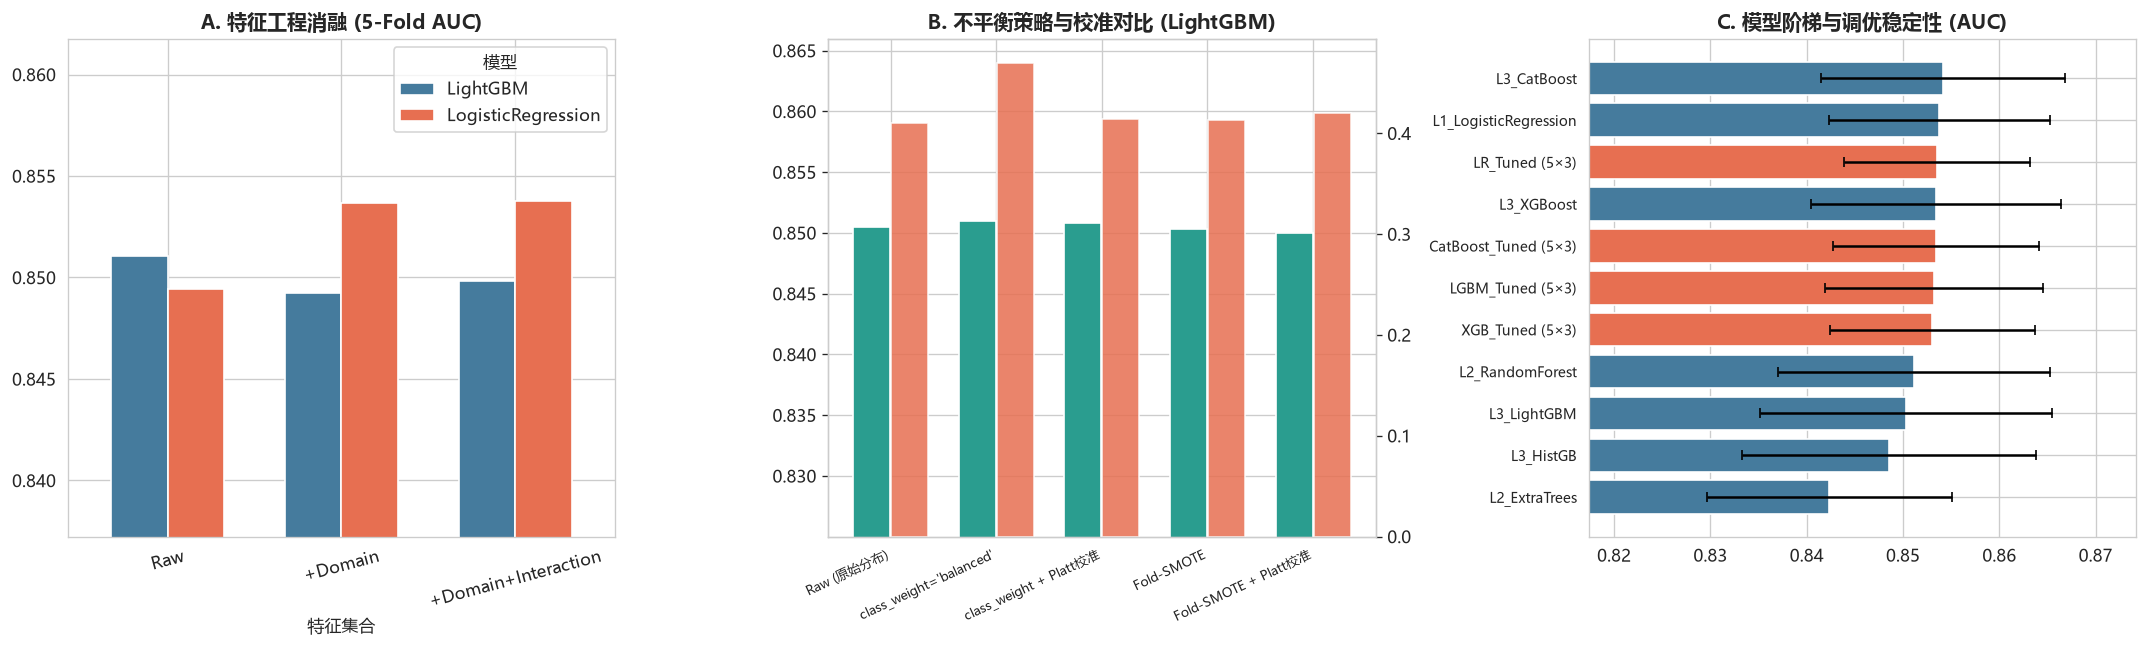

In [8]:
# Optuna 调优
def tune_study(obj_fn, n_trials, seed):
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
    st.optimize(obj_fn, n_trials=n_trials, show_progress_bar=False)
    return st.best_params

def obj_lr(trial):
    c_val = trial.suggest_float("C", 0.01, 10.0, log=True)
    l1_r = trial.suggest_float("l1_ratio", 0.0, 1.0)
    fs = trial.suggest_categorical("feat_set", ["+Domain", "+Domain+Interaction"])
    return eval_cv(lambda: make_pipe(LogisticRegression(C=c_val, l1_ratio=l1_r, solver="saga", max_iter=3000, tol=1e-3, random_state=RANDOM_STATE), FEATURE_CONFIGS[fs], True), X_train, y_train, cv_splits)["roc_auc_mean"]

def obj_lgb(trial):
    p = {
        "n_estimators": trial.suggest_int("n_estimators", 80, 400),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 31),
        "max_depth": trial.suggest_int("max_depth", 3, 7),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 100),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    return eval_cv(lambda: make_pipe(lgb.LGBMClassifier(**p, subsample_freq=1, random_state=RANDOM_STATE, n_jobs=4, verbose=-1), tree_feat_cfg, False), X_train, y_train, cv_splits)["roc_auc_mean"]

def obj_xgb(trial):
    p = {
        "n_estimators": trial.suggest_int("n_estimators", 80, 400),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "min_child_weight": trial.suggest_int("min_child_weight", 5, 50),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
    }
    return eval_cv(lambda: make_pipe(XGBClassifier(**p, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=4), tree_feat_cfg, False), X_train, y_train, cv_splits)["roc_auc_mean"]

def obj_cat(trial):
    p = {
        "iterations": trial.suggest_int("iterations", 120, 400),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "depth": trial.suggest_int("depth", 3, 7),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.1, 5.0),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
    }
    return eval_cv(lambda: make_pipe(CatBoostClassifier(**p, random_seed=RANDOM_STATE, thread_count=-1, allow_writing_files=False, verbose=0), tree_feat_cfg, False), X_train, y_train, cv_splits)["roc_auc_mean"]

best_lr = tune_study(obj_lr, 12, RANDOM_STATE)
best_lgb = tune_study(obj_lgb, 15, RANDOM_STATE + 1)
best_xgb = tune_study(obj_xgb, 15, RANDOM_STATE + 2)
best_cat = tune_study(obj_cat, 12, RANDOM_STATE + 3)

lr_fc_tuned = FEATURE_CONFIGS[best_lr.pop("feat_set")]
tuned_factories = {
    "LR_Tuned": lambda: make_pipe(LogisticRegression(**best_lr, solver="saga", max_iter=3000, tol=1e-3, random_state=RANDOM_STATE), lr_fc_tuned, True),
    "LGBM_Tuned": lambda: make_pipe(lgb.LGBMClassifier(**best_lgb, subsample_freq=1, random_state=RANDOM_STATE, n_jobs=4, verbose=-1), tree_feat_cfg, False),
    "XGB_Tuned": lambda: make_pipe(XGBClassifier(**best_xgb, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=4), tree_feat_cfg, False),
    "CatBoost_Tuned": lambda: make_pipe(CatBoostClassifier(**best_cat, random_seed=RANDOM_STATE, thread_count=-1, allow_writing_files=False, verbose=0), tree_feat_cfg, False),
}

tuned_res = {name: eval_cv(fac, X_train, y_train, cv_splits, fit_folds=True) for name, fac in tuned_factories.items()}

# 5x3 Repeated Stratified CV 稳定性复核
rep_splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE).split(X_train, strata_train))
rep_rows = []
for name, fac in tuned_factories.items():
    r = eval_cv(fac, X_train, y_train, rep_splits)
    rep_rows.append({"模型": name, "5x3_ROC_AUC": r["roc_auc_mean"], "AUC_Std": r["roc_auc_std"], "5x3_PR_AUC": r["pr_auc_mean"], "5x3_LogLoss": r["log_loss_mean"], "5x3_Brier": r["brier_mean"]})
repeated_df = pd.DataFrame(rep_rows).sort_values("5x3_ROC_AUC", ascending=False).reset_index(drop=True)
display(repeated_df.round(4))

# 绘制 CV 总览图
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
piv = ablation_df.pivot(index="特征集合", columns="模型", values="CV_ROC_AUC").reindex(["Raw", "+Domain", "+Domain+Interaction"])
piv.plot(kind="bar", ax=axes[0], color=["#457B9D", "#E76F51"], width=0.65)
axes[0].set_title("A. 特征工程消融 (5-Fold AUC)", fontweight="bold")
axes[0].set_ylim(max(0.80, piv.min().min() - 0.012), piv.max().max() + 0.008)
axes[0].tick_params(axis="x", rotation=15)

sub_imb = imbalance_df[imbalance_df["模型"] == "LightGBM"]
x = np.arange(len(sub_imb))
axes[1].bar(x - 0.18, sub_imb["roc_auc"], width=0.35, color="#2A9D8F", label="OOF ROC-AUC")
axes[1].set_ylim(max(0.75, sub_imb["roc_auc"].min() - 0.025), sub_imb["roc_auc"].max() + 0.015)
axes[1].set_xticks(x)
axes[1].set_xticklabels(sub_imb["不平衡策略"], rotation=25, ha="right", fontsize=8)
ax2 = axes[1].twinx()
ax2.bar(x + 0.18, sub_imb["log_loss"], width=0.35, color="#E76F51", alpha=0.85, label="OOF LogLoss")
ax2.grid(False)
axes[1].set_title("B. 不平衡策略与校准对比 (LightGBM)", fontweight="bold")

comb = pd.concat([
    benchmark_df[~benchmark_df["模型"].str.startswith("L0_")][["模型", "ROC_AUC", "AUC_Std"]],
    repeated_df.assign(模型=repeated_df["模型"] + " (5×3)").rename(columns={"5x3_ROC_AUC": "ROC_AUC"})[["模型", "ROC_AUC", "AUC_Std"]],
], ignore_index=True).sort_values("ROC_AUC")
yp = np.arange(len(comb))
axes[2].barh(yp, comb["ROC_AUC"], xerr=comb["AUC_Std"], color=["#E76F51" if "5×3" in m else "#457B9D" for m in comb["模型"]], capsize=3)
axes[2].set_yticks(yp)
axes[2].set_yticklabels(comb["模型"], fontsize=8.5)
axes[2].set_xlim(max(0.76, comb["ROC_AUC"].min() - 0.025), comb["ROC_AUC"].max() + 0.02)
axes[2].set_title("C. 模型阶梯与调优稳定性 (AUC)", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. 概率校准、多模型融合与 OOF 阈值寻优

In [9]:
class PlattCalibrator(BaseEstimator, ClassifierMixin):
    def fit(self, probs, y):
        z = logit(np.clip(probs, 1e-6, 1 - 1e-6)).reshape(-1, 1)
        self.lr_ = LogisticRegression(C=1e6, max_iter=1000).fit(z, y)
        return self
    def transform(self, probs):
        z = logit(np.clip(probs, 1e-6, 1 - 1e-6)).reshape(-1, 1)
        return self.lr_.predict_proba(z)[:, 1]


def fit_simplex_weights(P, y):
    P_c = np.clip(P, 1e-6, 1 - 1e-6)
    res = minimize(
        lambda w: log_loss(y, np.clip(P_c @ w, 1e-6, 1 - 1e-6)),
        np.full(P.shape[1], 1.0 / P.shape[1]),
        method="SLSQP",
        bounds=[(0, 1)] * P.shape[1],
        constraints=[{"type": "eq", "fun": lambda w: np.sum(w) - 1.0}],
    )
    w = np.maximum(res.x, 0)
    return w / w.sum()


model_names = list(tuned_res.keys())
P_oof = np.column_stack([tuned_res[m]["oof"] for m in model_names])
nested_oof = {
    **{m: tuned_res[m]["oof"] for m in model_names},
    "Ensemble_Equal_Vote": P_oof.mean(axis=1),
    "Ensemble_Weighted_Blend": np.zeros(len(y_train)),
    "Ensemble_Weighted_Platt": np.zeros(len(y_train)),
    "Ensemble_Weighted_Isotonic": np.zeros(len(y_train)),
    "Ensemble_Stacking_LR": np.zeros(len(y_train)),
}
for tr, va in cv_splits:
    w = fit_simplex_weights(P_oof[tr], y_train[tr])
    b_tr, b_va = P_oof[tr] @ w, P_oof[va] @ w
    nested_oof["Ensemble_Weighted_Blend"][va] = b_va
    nested_oof["Ensemble_Weighted_Platt"][va] = PlattCalibrator().fit(b_tr, y_train[tr]).transform(b_va)
    nested_oof["Ensemble_Weighted_Isotonic"][va] = IsotonicRegression(out_of_bounds="clip").fit(b_tr, y_train[tr]).transform(b_va)
    meta = LogisticRegression(C=1.0, max_iter=1000).fit(logit(np.clip(P_oof[tr], 1e-6, 1-1e-6)), y_train[tr])
    nested_oof["Ensemble_Stacking_LR"][va] = meta.predict_proba(logit(np.clip(P_oof[va], 1e-6, 1-1e-6)))[:, 1]

oof_comp_df = pd.DataFrame([{"候选模型": k, **calc_metrics(y_train, v)} for k, v in nested_oof.items()]).sort_values(["roc_auc", "log_loss"], ascending=[False, True]).reset_index(drop=True)
max_auc = oof_comp_df["roc_auc"].max()
champion_name = str(oof_comp_df[oof_comp_df["roc_auc"] >= max_auc - 0.0003].sort_values("log_loss").iloc[0]["候选模型"])

final_weights = fit_simplex_weights(P_oof, y_train)
final_platt = PlattCalibrator().fit(P_oof @ final_weights, y_train)
final_iso = IsotonicRegression(out_of_bounds="clip").fit(P_oof @ final_weights, y_train)
final_stack = LogisticRegression(C=1.0, max_iter=1000).fit(logit(np.clip(P_oof, 1e-6, 1-1e-6)), y_train)

print("OOF 选定主模型:", champion_name)
print("融合权重:", {m: round(float(w), 4) for m, w in zip(model_names, final_weights)})
display(oof_comp_df.round(4))

# 在 Champion OOF 上优化业务与分类阈值
champ_oof = nested_oof[champion_name]
grid = np.linspace(0.05, 0.90, 171)
curve_rows = []
for t in grid:
    ypred = champ_oof >= t
    ltv = monthly_train * BIZ_CFG.ltv_horizon_months
    cost = BIZ_CFG.contact_cost + BIZ_CFG.offer_rate * monthly_train
    prof = float((y_train[ypred] * BIZ_CFG.retention_success_rate * ltv[ypred]).sum() - cost[ypred].sum())
    curve_rows.append({"threshold": t, "f1": f1_score(y_train, ypred, zero_division=0), "f2": fbeta_score(y_train, ypred, beta=2.0, zero_division=0), "net_profit": prof})
curve_df_oof = pd.DataFrame(curve_rows)
thresholds = {
    "default_0.5": 0.50,
    "f1_opt": float(curve_df_oof.loc[curve_df_oof["f1"].idxmax(), "threshold"]),
    "f2_opt": float(curve_df_oof.loc[curve_df_oof["f2"].idxmax(), "threshold"]),
    "profit_opt": float(curve_df_oof.loc[curve_df_oof["net_profit"].idxmax(), "threshold"]),
}
print("OOF 最优阈值:", thresholds)

OOF 选定主模型: Ensemble_Weighted_Blend
融合权重: {'LR_Tuned': 0.4526, 'LGBM_Tuned': 0.1861, 'XGB_Tuned': 0.0, 'CatBoost_Tuned': 0.3613}


,候选模型,roc_auc,pr_auc,log_loss,brier,ece
0,Ensemble_Weighted_Blend,0.8545,0.6791,0.4051,0.1310,0.0095
1,Ensemble_Equal_Vote,0.8545,0.6792,0.4052,0.1310,0.0081
2,Ensemble_Weighted_Platt,0.8543,0.6784,0.4054,0.1311,0.0108
3,CatBoost_Tuned,0.8542,0.6792,0.4056,0.1311,0.0085
4,Ensemble_Stacking_LR,0.8541,0.6779,0.4056,0.1311,0.0119
5,LR_Tuned,0.8537,0.6783,0.4059,0.1312,0.0143
6,LGBM_Tuned,0.8532,0.6752,0.4068,0.1316,0.0085
7,XGB_Tuned,0.8530,0.6764,0.4078,0.1317,0.0121
8,Ensemble_Weighted_Isotonic,0.8505,0.6634,0.4188,0.1319,0.0077


OOF 最优阈值: {'default_0.5': 0.5, 'f1_opt': 0.345, 'f2_opt': 0.16, 'profit_opt': 0.175}


## 8. 锁仓测试集（n = 1,409）一次性盲测验收

,模型,roc_auc,pr_auc,log_loss,brier,ece,AUC_95CI_Low,AUC_95CI_High
0,LGBM_Tuned,0.8345,0.6296,0.4296,0.1411,0.0249,0.8131,0.8566
1,Ensemble_Equal_Vote,0.8345,0.6287,0.4291,0.1410,0.0270,0.8131,0.8562
2,XGB_Tuned,0.8343,0.6278,0.4303,0.1414,0.0260,0.8123,0.8562
3,Ensemble_Weighted_Blend,0.8342,0.6284,0.4293,0.1411,0.0236,0.8125,0.8563
4,Ensemble_Weighted_Platt,0.8342,0.6284,0.4299,0.1413,0.0252,0.8125,0.8563
5,Ensemble_Stacking_LR,0.8340,0.6283,0.4301,0.1413,0.0241,0.8123,0.8560
6,LR_Tuned,0.8338,0.6264,0.4304,0.1414,0.0264,0.8119,0.8559
7,Ensemble_Weighted_Isotonic,0.8331,0.6126,0.4301,0.1411,0.0293,0.8114,0.8555
8,CatBoost_Tuned,0.8321,0.6259,0.4308,0.1417,0.0208,0.8096,0.8542


配对 Bootstrap (Ensemble_Weighted_Blend - LR_Tuned): ΔAUC=+0.0004, p=0.7120


配对 Bootstrap (Ensemble_Weighted_Blend - CatBoost_Tuned): ΔAUC=+0.0021, p=0.0520


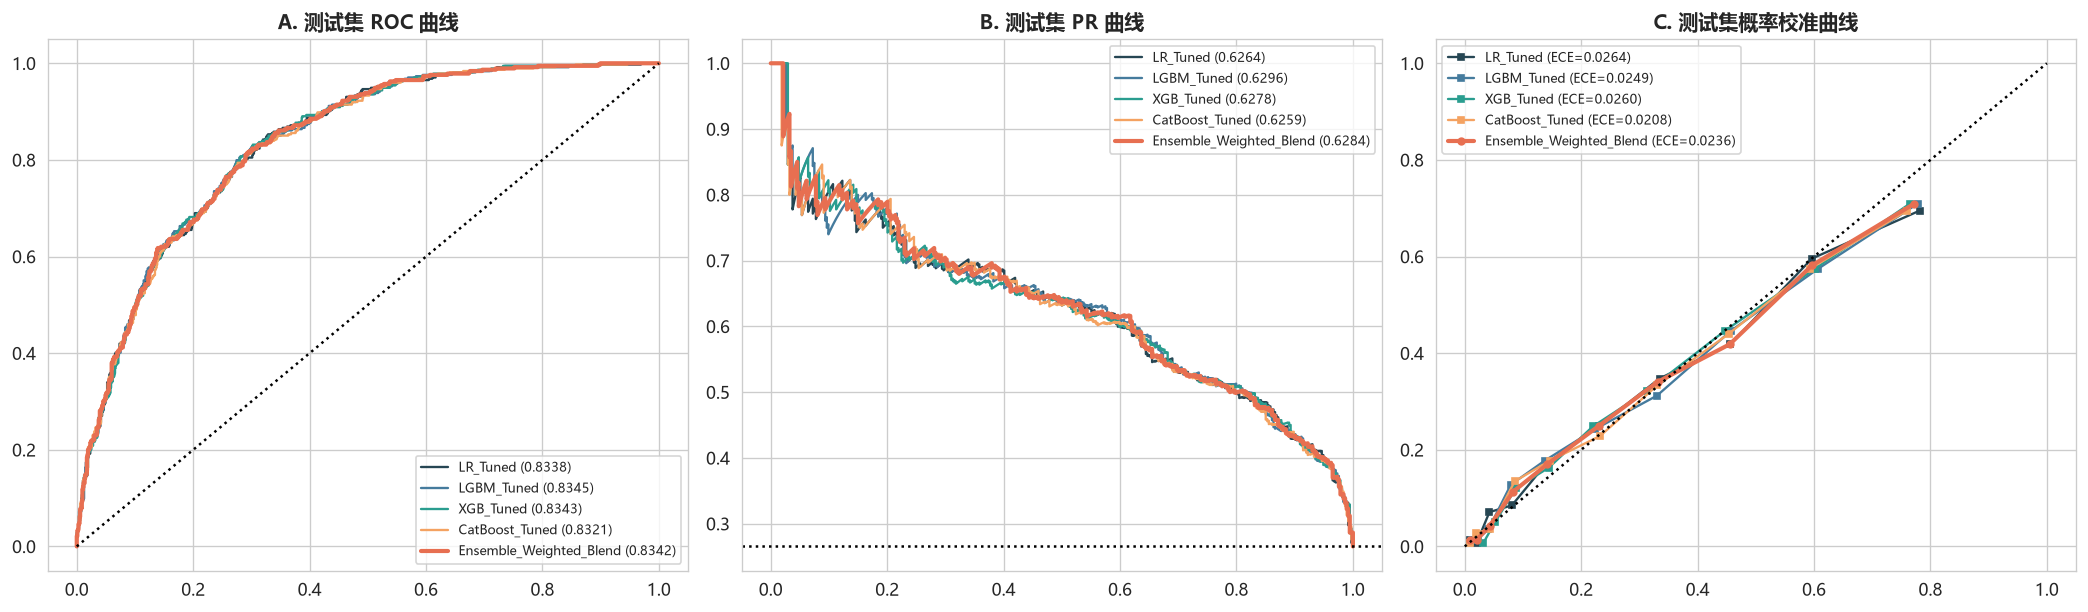

In [10]:
def predict_test_all(X_df):
    base = {m: np.mean(np.column_stack([p.predict_proba(X_df)[:, 1] for p in tuned_res[m]["pipes"]]), axis=1) for m in model_names}
    P = np.column_stack([base[m] for m in model_names])
    w_b = P @ final_weights
    return {
        **base,
        "Ensemble_Equal_Vote": P.mean(axis=1),
        "Ensemble_Weighted_Blend": w_b,
        "Ensemble_Weighted_Platt": final_platt.transform(w_b),
        "Ensemble_Weighted_Isotonic": final_iso.transform(w_b),
        "Ensemble_Stacking_LR": final_stack.predict_proba(logit(np.clip(P, 1e-6, 1-1e-6)))[:, 1],
    }

test_cands = predict_test_all(X_test)
champ_test_prob = test_cands[champion_name]

def boot_ci(yt, yp, fn, n_boot=1000):
    rng = np.random.default_rng(RANDOM_STATE)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(yt), len(yt))
        if len(np.unique(yt[idx])) == 2:
            vals.append(fn(yt[idx], yp[idx]))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(lo), float(hi)

test_rows = []
for k, v in test_cands.items():
    m = calc_metrics(y_test, v)
    lo, hi = boot_ci(y_test, v, roc_auc_score)
    test_rows.append({"模型": k, **m, "AUC_95CI_Low": lo, "AUC_95CI_High": hi})
test_comp_df = pd.DataFrame(test_rows).sort_values(["roc_auc", "log_loss"], ascending=[False, True]).reset_index(drop=True)
display(test_comp_df.round(4))

# 配对 Bootstrap 检验
best_tree = str(oof_comp_df[oof_comp_df["候选模型"].isin(["LGBM_Tuned", "XGB_Tuned", "CatBoost_Tuned"])].iloc[0]["候选模型"])
for base_name in ["LR_Tuned", best_tree]:
    rng = np.random.default_rng(RANDOM_STATE)
    diffs = [roc_auc_score(y_test[idx], champ_test_prob[idx]) - roc_auc_score(y_test[idx], test_cands[base_name][idx])
             for idx in (rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)) if len(np.unique(y_test[idx])) == 2]
    diff_obs = roc_auc_score(y_test, champ_test_prob) - roc_auc_score(y_test, test_cands[base_name])
    pval = min(1.0, 2.0 * min(np.mean(np.array(diffs) <= 0), np.mean(np.array(diffs) >= 0)))
    print(f"配对 Bootstrap ({champion_name} - {base_name}): ΔAUC={diff_obs:+.4f}, p={pval:.4f}")

# ROC / PR / Calibration 三联图
fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2))
plot_keys = list(dict.fromkeys(["LR_Tuned", "LGBM_Tuned", "XGB_Tuned", "CatBoost_Tuned", champion_name]))
palette = ["#264653", "#457B9D", "#2A9D8F", "#F4A261", "#E76F51"]
for i, k in enumerate(plot_keys):
    yp = test_cands[k]
    fpr, tpr, _ = roc_curve(y_test, yp)
    prec, rec, _ = precision_recall_curve(y_test, yp)
    pt, pp = calibration_curve(y_test, np.clip(yp, 1e-7, 1-1e-7), n_bins=10, strategy="quantile")
    lw = 2.5 if k == champion_name else 1.4
    axes[0].plot(fpr, tpr, lw=lw, color=palette[i], label=f"{k} ({roc_auc_score(y_test, yp):.4f})")
    axes[1].plot(rec, prec, lw=lw, color=palette[i], label=f"{k} ({average_precision_score(y_test, yp):.4f})")
    axes[2].plot(pp, pt, marker="o" if k == champion_name else "s", ms=4, lw=lw, color=palette[i], label=f"{k} (ECE={compute_ece(y_test, yp):.4f})")

axes[0].plot([0,1],[0,1],"k:"); axes[0].set_title("A. 测试集 ROC 曲线", fontweight="bold"); axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color="k", ls=":"); axes[1].set_title("B. 测试集 PR 曲线", fontweight="bold"); axes[1].legend(fontsize=8)
axes[2].plot([0,1],[0,1],"k:"); axes[2].set_title("C. 测试集概率校准曲线", fontweight="bold"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. 业务收益、Top-K 增益、敏感性热力图与子群切片审计

,策略,n_targeted,target_rate,precision,capture_rate,total_cost,net_profit,roi_pct
0,默认阈值 (t=0.50),305,0.216,0.636,0.519,8663.275,23767.445,274.347
1,F1 最优 (t=0.34),478,0.339,0.540,0.690,13609.535,29302.915,215.312
2,F2 最优 (t=0.16),741,0.526,0.444,0.880,20270.055,32674.830,161.198
3,全局利润最优 (t=0.17),717,0.509,0.455,0.872,19630.650,33005.010,168.130
4,个体期望价值规则 (EV>0),697,0.495,0.461,0.858,19521.800,32904.805,168.554
5,基线: 全部挽留,1409,1.000,0.265,1.000,34030.705,24839.435,72.991
6,基线: 等比例随机挽留,708,0.502,0.258,0.489,16978.095,12167.280,71.665
7,基线: 全部不挽留,0,0.000,0.000,0.000,0.000,0.000,0.000
8,理论上限: Oracle 全知,374,0.265,1.000,1.000,10280.020,48590.120,472.666


,Top_K%,触达人数,Precision@K,流失捕获率,Lift,流失月费捕获(风险排),流失月费捕获(风险×月费排)
0,5,71,0.7746,0.1471,2.9184,0.1551,0.1740
1,10,141,0.7092,0.2674,2.6719,0.2901,0.3351
2,15,212,0.6887,0.3904,2.5945,0.4191,0.4372
3,20,282,0.6454,0.4866,2.4314,0.5165,0.5637
4,25,353,0.6176,0.5829,2.3266,0.6156,0.6462
5,30,423,0.5697,0.6444,2.1464,0.6790,0.7202
6,40,564,0.5124,0.7727,1.9304,0.8060,0.8353
7,50,705,0.4596,0.8663,1.7314,0.8869,0.9038


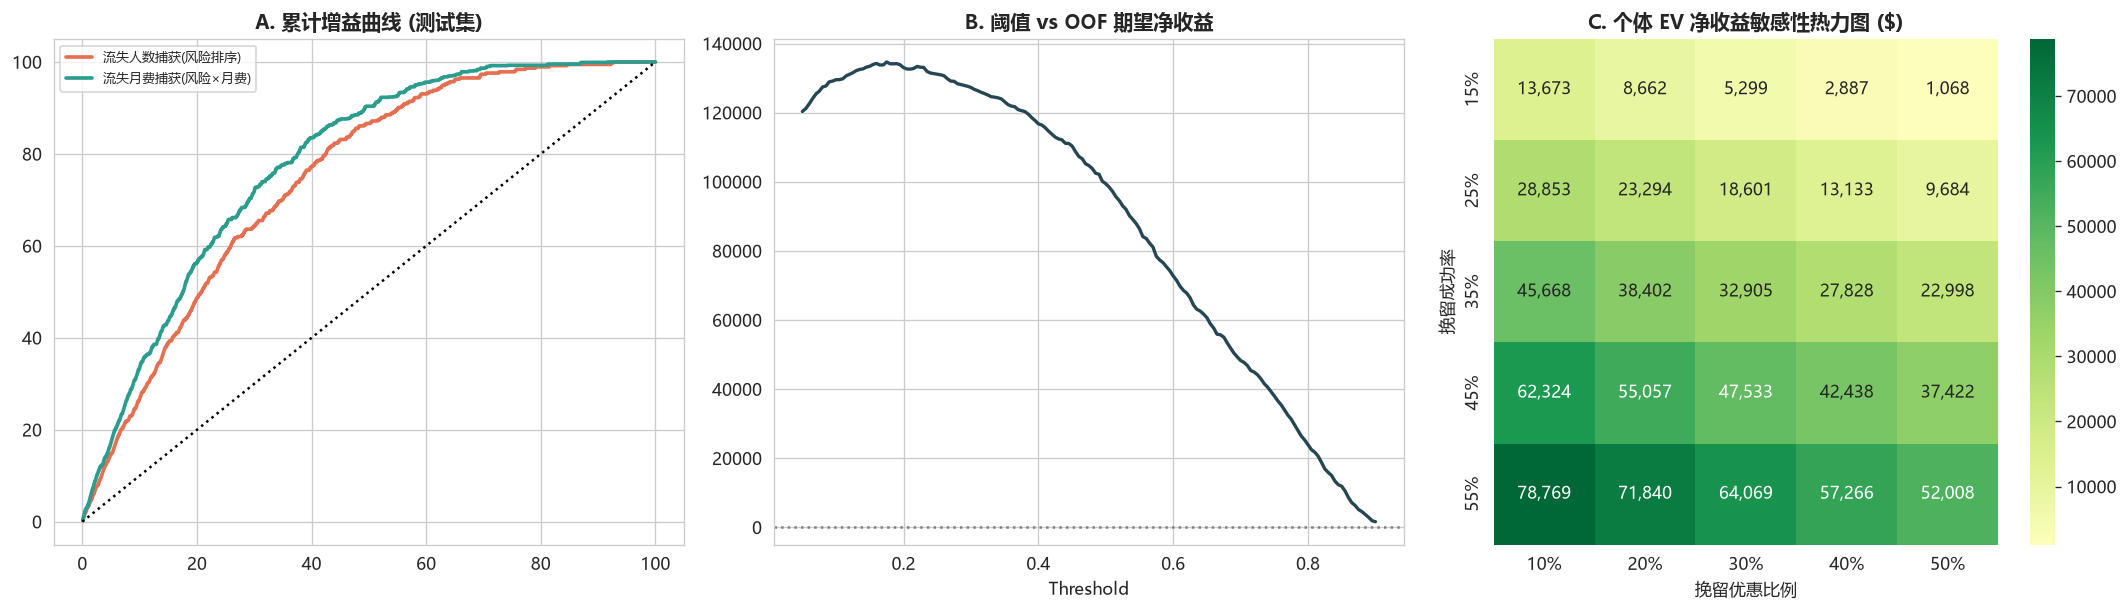

In [11]:
monthly_test = X_test["MonthlyCharges"].to_numpy(float)

def calc_profit_stats(yt, mask, charges, cfg: BusinessConfig):
    ltv = charges * cfg.ltv_horizon_months
    cost = cfg.contact_cost + cfg.offer_rate * charges
    if mask.sum() == 0:
        return dict(net_profit=0.0, total_cost=0.0, roi_pct=0.0, n_targeted=0, target_rate=0.0, capture_rate=0.0, precision=0.0)
    saved = float((yt[mask] * cfg.retention_success_rate * ltv[mask]).sum())
    tcost = float(cost[mask].sum())
    net = saved - tcost
    return {
        "n_targeted": int(mask.sum()),
        "target_rate": float(mask.mean()),
        "precision": float(yt[mask].mean()),
        "capture_rate": float(yt[mask].sum() / yt.sum()),
        "total_cost": tcost,
        "net_profit": net,
        "roi_pct": net / tcost * 100.0,
    }

ltv_t = monthly_test * BIZ_CFG.ltv_horizon_months
cost_t = BIZ_CFG.contact_cost + BIZ_CFG.offer_rate * monthly_test
ev_profit_t = champ_test_prob * BIZ_CFG.retention_success_rate * ltv_t - cost_t
ev_mask_t = ev_profit_t > 0
rng = np.random.default_rng(RANDOM_STATE)

biz_rows = []
for name, msk in [
    ("默认阈值 (t=0.50)", champ_test_prob >= 0.50),
    (f"F1 最优 (t={thresholds['f1_opt']:.2f})", champ_test_prob >= thresholds["f1_opt"]),
    (f"F2 最优 (t={thresholds['f2_opt']:.2f})", champ_test_prob >= thresholds["f2_opt"]),
    (f"全局利润最优 (t={thresholds['profit_opt']:.2f})", champ_test_prob >= thresholds["profit_opt"]),
    ("个体期望价值规则 (EV>0)", ev_mask_t),
    ("基线: 全部挽留", np.ones(len(y_test), bool)),
    ("基线: 等比例随机挽留", rng.random(len(y_test)) < ev_mask_t.mean()),
    ("基线: 全部不挽留", np.zeros(len(y_test), bool)),
    ("理论上限: Oracle 全知", (y_test == 1) & ((BIZ_CFG.retention_success_rate * ltv_t - cost_t) > 0)),
]:
    biz_rows.append({"策略": name, **calc_profit_stats(y_test, msk, monthly_test, BIZ_CFG)})
biz_df = pd.DataFrame(biz_rows)
display(biz_df.round(3))

# Top-K Lift 表
ord_p = np.argsort(-champ_test_prob)
ord_v = np.argsort(-(champ_test_prob * monthly_test))
lift_rows = []
for k in (5, 10, 15, 20, 25, 30, 40, 50):
    m = int(np.ceil(len(y_test) * k / 100.0))
    ip, iv = ord_p[:m], ord_v[:m]
    lift_rows.append({
        "Top_K%": k, "触达人数": m,
        "Precision@K": y_test[ip].mean(),
        "流失捕获率": y_test[ip].sum() / y_test.sum(),
        "Lift": y_test[ip].mean() / y_test.mean(),
        "流失月费捕获(风险排)": (y_test[ip] * monthly_test[ip]).sum() / (y_test * monthly_test).sum(),
        "流失月费捕获(风险×月费排)": (y_test[iv] * monthly_test[iv]).sum() / (y_test * monthly_test).sum(),
    })
display(pd.DataFrame(lift_rows).round(4))

# 增益曲线 + 利润曲线 + 2D 敏感性热力图
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
pct_x = np.arange(1, len(y_test) + 1) / len(y_test) * 100
axes[0].plot(pct_x, np.cumsum(y_test[ord_p]) / y_test.sum() * 100, color="#E76F51", lw=2.2, label="流失人数捕获(风险排序)")
axes[0].plot(pct_x, np.cumsum(y_test[ord_v] * monthly_test[ord_v]) / (y_test * monthly_test).sum() * 100, color="#2A9D8F", lw=2.2, label="流失月费捕获(风险×月费)")
axes[0].plot([0,100],[0,100],"k:")
axes[0].set_title("A. 累计增益曲线 (测试集)", fontweight="bold"); axes[0].legend(fontsize=8)

axes[1].plot(curve_df_oof["threshold"], curve_df_oof["net_profit"], color="#264653", lw=2)
axes[1].axhline(0, color="gray", ls=":")
axes[1].set_title("B. 阈值 vs OOF 期望净收益", fontweight="bold"); axes[1].set_xlabel("Threshold")

srs = [0.15, 0.25, 0.35, 0.45, 0.55]
ors = [0.10, 0.20, 0.30, 0.40, 0.50]
sens = pd.DataFrame(index=[f"{int(s*100)}%" for s in srs], columns=[f"{int(o*100)}%" for o in ors], dtype=float)
for s in srs:
    for o in ors:
        c = BusinessConfig(offer_rate=o, retention_success_rate=s)
        m_ev = (champ_test_prob * s * ltv_t - (c.contact_cost + o * monthly_test)) > 0
        sens.loc[f"{int(s*100)}%", f"{int(o*100)}%"] = calc_profit_stats(y_test, m_ev, monthly_test, c)["net_profit"]
sns.heatmap(sens, annot=True, fmt=",.0f", cmap="RdYlGn", center=0.0, ax=axes[2])
axes[2].set_title("C. 个体 EV 净收益敏感性热力图 ($)", fontweight="bold")
axes[2].set_xlabel("挽留优惠比例"); axes[2].set_ylabel("挽留成功率")
plt.tight_layout()
plt.show()

,客户数,真实流失率,平均月费,期望净收益合计
risk_value_quadrant,,,,
低风险-低价值,479,0.069,34.882,-5486.927
低风险-高价值,213,0.070,92.762,-3703.498
高风险-低价值,253,0.379,46.653,6184.052
高风险-高价值,464,0.496,89.832,28429.373


,维度,分组,样本数,真实流失率,平均预测概率,校准偏差,ROC_AUC,Recall
0,Contract,Month-to-month,775,0.4271,0.4350,0.0079,0.7291,0.9426
1,Contract,One year,294,0.1122,0.1036,-0.0086,0.6962,0.4242
2,Contract,Two year,340,0.0294,0.0311,0.0017,0.7670,0.0000
3,tenure_group,0m,5,0.0000,0.0665,0.0665,NaN,0.0000
4,tenure_group,1-6m,306,0.4967,0.5353,0.0385,0.7098,0.9868
5,tenure_group,13-24m,187,0.2834,0.2819,-0.0015,0.8177,0.9057
6,tenure_group,25-48m,342,0.1988,0.2000,0.0012,0.7519,0.7500
7,tenure_group,49-72m,430,0.1000,0.0884,-0.0116,0.8123,0.5116
8,tenure_group,7-12m,139,0.4173,0.3950,-0.0223,0.8751,0.9483
9,InternetService,DSL,465,0.2000,0.1950,-0.0050,0.7878,0.7097


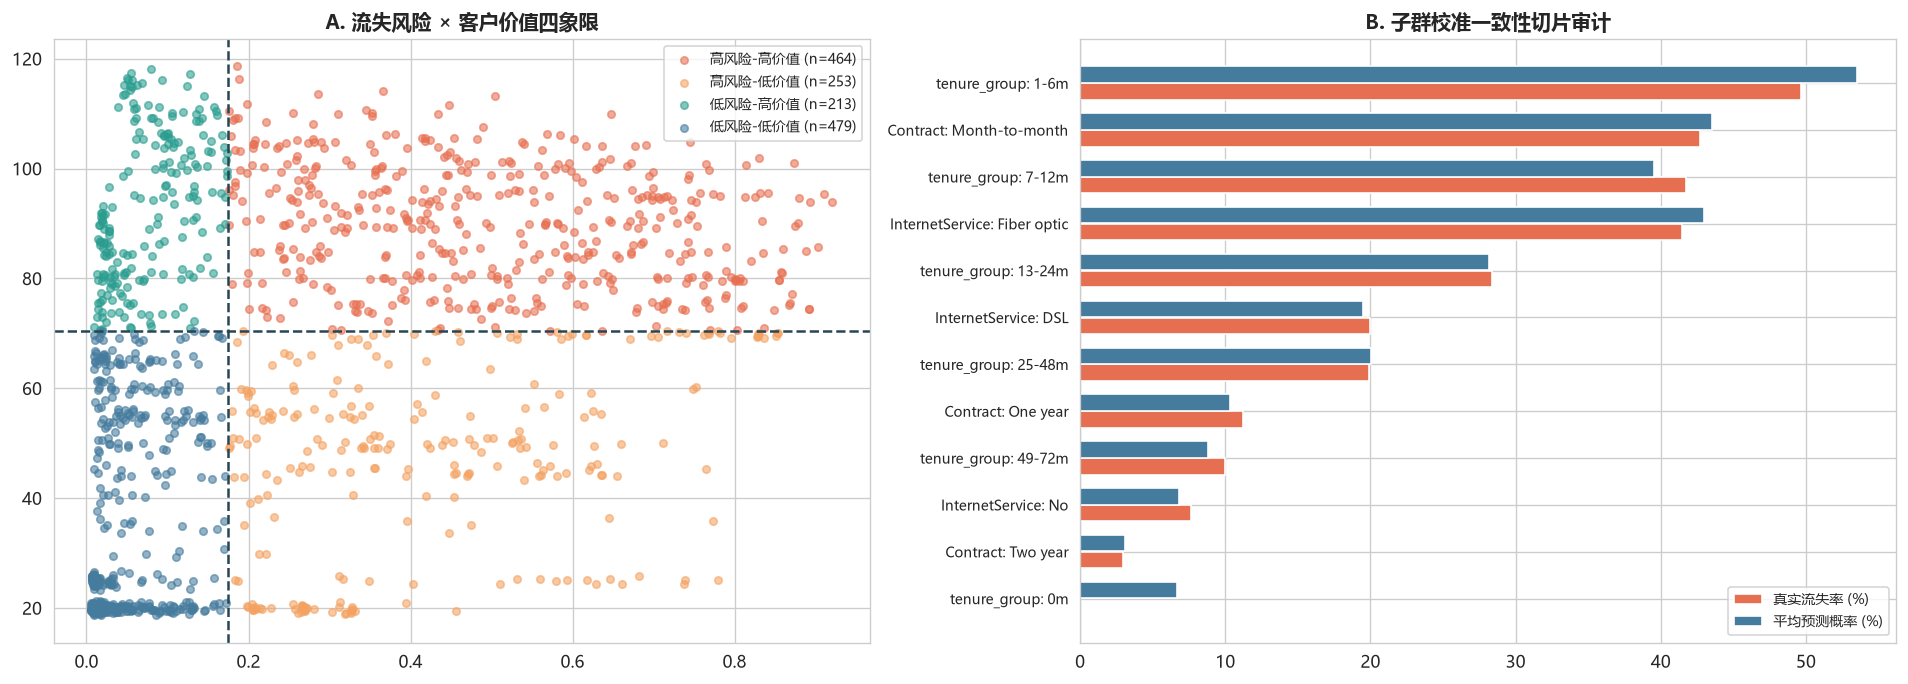

In [12]:
# 风险×价值四象限 & 子群公平性切片审计
val_med = float(np.median(monthly_train))
prob_thr = thresholds["profit_opt"]
quads = np.where(
    (champ_test_prob >= prob_thr) & (monthly_test >= val_med), "高风险-高价值",
    np.where((champ_test_prob >= prob_thr) & (monthly_test < val_med), "高风险-低价值",
             np.where((champ_test_prob < prob_thr) & (monthly_test >= val_med), "低风险-高价值", "低风险-低价值"))
)
scored_test = pd.DataFrame({
    "customerID": ids_test, "Contract": X_test["Contract"], "tenure": X_test["tenure"],
    "MonthlyCharges": monthly_test, "churn_prob": champ_test_prob,
    "expected_net_profit": ev_profit_t, "risk_value_quadrant": quads, "actual_churn": y_test,
})
display(scored_test.groupby("risk_value_quadrant").agg(客户数=("customerID", "count"), 真实流失率=("actual_churn", "mean"), 平均月费=("MonthlyCharges", "mean"), 期望净收益合计=("expected_net_profit", "sum")).round(3))

df_sl = X_test.copy()
df_sl["tenure_group"] = pd.cut(df_sl["tenure"], bins=[-1,0,6,12,24,48,1000], labels=["0m","1-6m","7-12m","13-24m","25-48m","49-72m"]).astype(str)
df_sl["_yt"], df_sl["_yp"] = y_test, champ_test_prob
slice_rows = []
for col in ["Contract", "tenure_group", "InternetService", "SeniorCitizen"]:
    for val, g in df_sl.groupby(col):
        yt, yp = g["_yt"].to_numpy(), g["_yp"].to_numpy()
        slice_rows.append({
            "维度": col, "分组": str(val), "样本数": len(g),
            "真实流失率": yt.mean(), "平均预测概率": yp.mean(),
            "校准偏差": yp.mean() - yt.mean(),
            "ROC_AUC": roc_auc_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan,
            "Recall": recall_score(yt, yp >= prob_thr, zero_division=0),
        })
slice_df = pd.DataFrame(slice_rows)
display(slice_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
for q, c in [("高风险-高价值", "#E76F51"), ("高风险-低价值", "#F4A261"), ("低风险-高价值", "#2A9D8F"), ("低风险-低价值", "#457B9D")]:
    s = scored_test[scored_test["risk_value_quadrant"] == q]
    axes[0].scatter(s["churn_prob"], s["MonthlyCharges"], c=c, alpha=0.58, s=20, label=f"{q} (n={len(s)})")
axes[0].axvline(prob_thr, color="#264653", ls="--"); axes[0].axhline(val_med, color="#264653", ls="--")
axes[0].set_title("A. 流失风险 × 客户价值四象限", fontweight="bold"); axes[0].legend(fontsize=8.5)

foc = slice_df[slice_df["维度"].isin(["Contract", "tenure_group", "InternetService"])].sort_values("真实流失率")
yp_s = np.arange(len(foc))
axes[1].barh(yp_s - 0.18, foc["真实流失率"] * 100, height=0.35, color="#E76F51", label="真实流失率 (%)")
axes[1].barh(yp_s + 0.18, foc["平均预测概率"] * 100, height=0.35, color="#457B9D", label="平均预测概率 (%)")
axes[1].set_yticks(yp_s)
axes[1].set_yticklabels(foc["维度"] + ": " + foc["分组"], fontsize=8.5)
axes[1].set_title("B. 子群校准一致性切片审计", fontweight="bold"); axes[1].legend(fontsize=8.5)
plt.tight_layout()
plt.show()

## 10. 可解释性分析（Logistic Odds Ratios & TreeSHAP）与高危挽留名单

,特征,coef,odds_ratio
18,contract_months,-0.5104,0.6003
9,log_total_charges,-0.4415,0.6431
31,InternetService_No,-0.4315,0.6495
8,log_tenure,-0.4149,0.6604
26,PhoneService_Yes,-0.4106,0.6633
15,has_fiber,0.3071,1.3595
47,PaperlessBilling_No,-0.2671,0.7656
39,TechSupport_Yes,-0.2328,0.7923
5,avg_monthly_charge,0.2165,1.2417
25,PhoneService_No,0.2110,1.2349


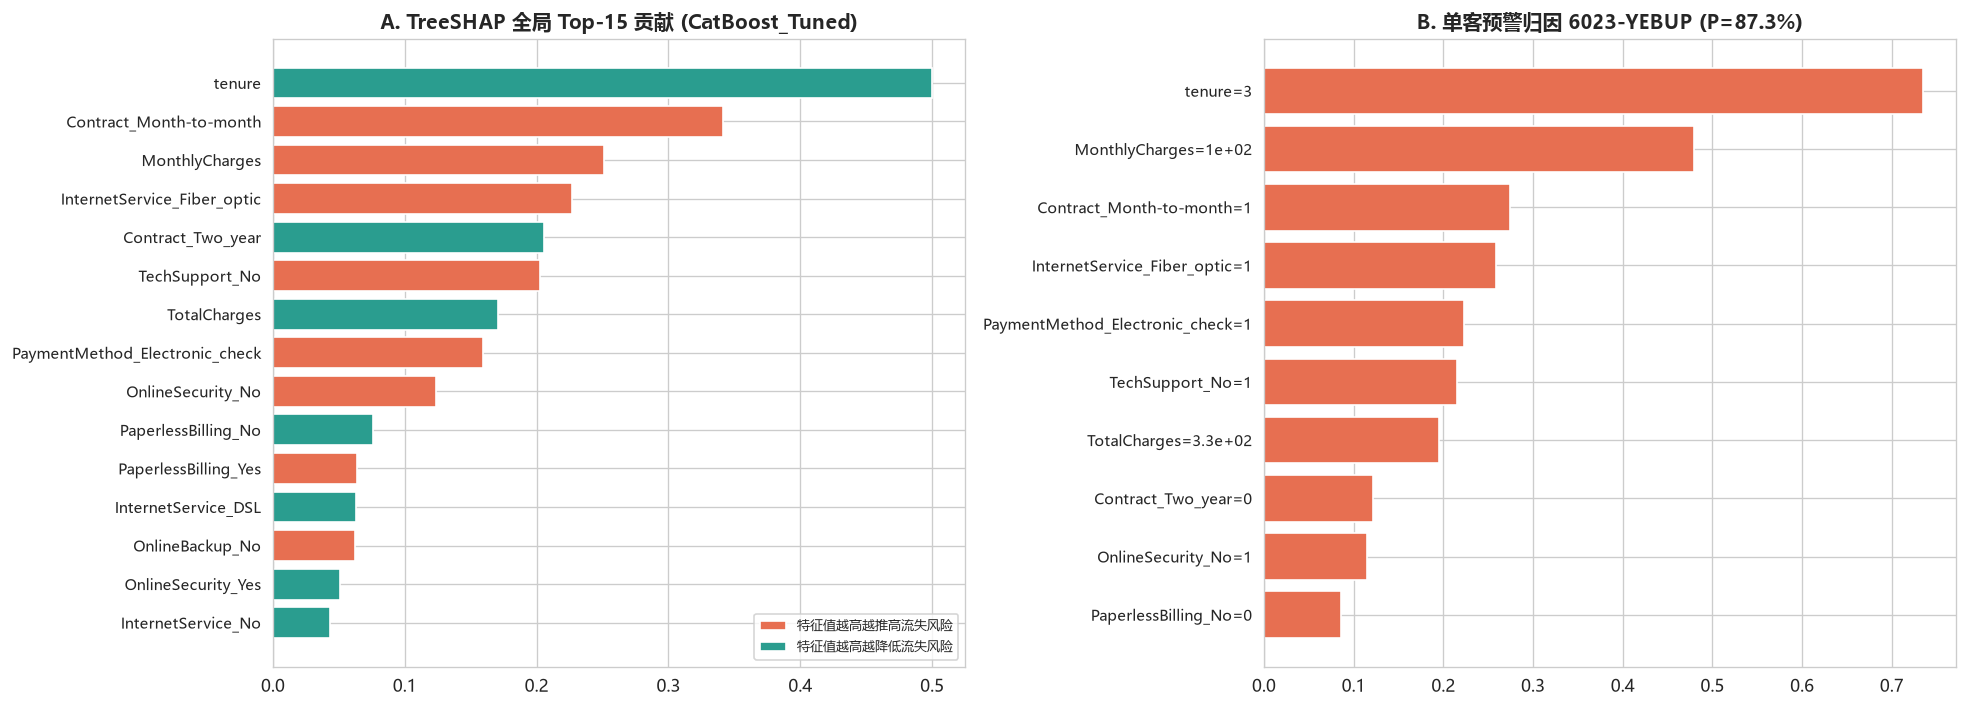

高风险-高价值优先挽留名单 Top 12：


,customerID,Contract,tenure,MonthlyCharges,churn_prob,expected_net_profit,risk_value_quadrant,top_3_drivers
297,6023-YEBUP,Month-to-month,3,100.95,0.873,149.806,高风险-高价值,tenure(+0.73); MonthlyCharges(+0.48); Contract...
1295,0295-PPHDO,Month-to-month,1,95.45,0.911,148.871,高风险-高价值,tenure(+1.07); TotalCharges(+0.50); MonthlyCha...
350,9300-AGZNL,Month-to-month,1,94.00,0.921,148.592,高风险-高价值,tenure(+1.07); TotalCharges(+0.54); MonthlyCha...
1037,4424-TKOPW,Month-to-month,2,93.85,0.893,142.887,高风险-高价值,tenure(+0.92); TotalCharges(+0.32); MonthlyCha...
1399,8884-ADFVN,Month-to-month,7,101.95,0.831,142.225,高风险-高价值,tenure(+0.60); MonthlyCharges(+0.48); Contract...
228,5567-WSELE,Month-to-month,3,94.60,0.879,141.272,高风险-高价值,tenure(+0.73); MonthlyCharges(+0.31); Internet...
27,4822-RVYBB,Month-to-month,8,100.60,0.814,136.794,高风险-高价值,tenure(+0.55); MonthlyCharges(+0.47); Contract...
31,6356-ELRKD,Month-to-month,1,95.60,0.841,135.195,高风险-高价值,tenure(+1.05); TotalCharges(+0.47); MonthlyCha...
506,1941-HOSAM,Month-to-month,1,90.10,0.878,134.090,高风险-高价值,tenure(+1.05); TotalCharges(+0.50); InternetSe...
116,4929-XIHVW,Month-to-month,2,95.50,0.832,133.178,高风险-高价值,tenure(+0.99); TotalCharges(+0.39); MonthlyCha...


In [13]:
# 1. Logistic Regression Odds Ratios
lr_full = clone(tuned_factories["LR_Tuned"]()).fit(X_train, y_train)
or_df = pd.DataFrame({
    "特征": lr_full.named_steps["prep"].get_feature_names_out(),
    "coef": lr_full.named_steps["clf"].coef_.ravel(),
})
or_df["odds_ratio"] = np.exp(or_df["coef"])
or_df["abs_coef"] = or_df["coef"].abs()
display(or_df.sort_values("abs_coef", ascending=False).head(10)[["特征", "coef", "odds_ratio"]].round(4))

# 2. TreeSHAP 全局与单客归因
tree_full = clone(tuned_factories[best_tree]()).fit(X_train, y_train)
X_test_enc = tree_full.named_steps["prep"].transform(X_test)
explainer = shap.TreeExplainer(tree_full.named_steps["clf"])
raw_sv = explainer.shap_values(X_test_enc)
sv = np.asarray(raw_sv[1] if isinstance(raw_sv, list) else raw_sv, dtype=float)
if sv.ndim == 3:
    sv = sv[:, :, 1]

feat_names = list(X_test_enc.columns)
shap_global = pd.DataFrame({"特征": feat_names, "mean_abs_shap": np.abs(sv).mean(axis=0), "mean_signed": sv.mean(axis=0)}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

drivers = []
for i in range(len(X_test_enc)):
    pos = np.where(sv[i] > 0)[0]
    chosen = pos[np.argsort(-sv[i][pos])[:3]] if len(pos) >= 3 else np.argsort(-np.abs(sv[i]))[:3]
    drivers.append("; ".join(f"{feat_names[j]}({sv[i][j]:+.2f})" for j in chosen))
scored_test["top_3_drivers"] = drivers

# 绘图: 全局 Top-15 SHAP + 最高净收益高危客户单客归因
top15 = shap_global.head(15).iloc[::-1]
hv = scored_test[scored_test["risk_value_quadrant"] == "高风险-高价值"]
c_idx = int(hv["expected_net_profit"].idxmax()) if len(hv) > 0 else int(scored_test["churn_prob"].idxmax())
top_loc = np.argsort(-np.abs(sv[c_idx]))[:10][::-1]

fig, axes = plt.subplots(1, 2, figsize=(16.5, 6))
colors_g = []
for feat in top15["特征"]:
    j = feat_names.index(feat)
    xc, sc = X_test_enc.iloc[:, j].to_numpy(float), sv[:, j]
    corr = float(np.corrcoef(xc, sc)[0, 1]) if np.std(xc) > 1e-12 and np.std(sc) > 1e-12 else 0.0
    colors_g.append("#E76F51" if corr >= 0 else "#2A9D8F")
axes[0].barh(np.arange(len(top15)), top15["mean_abs_shap"], color=colors_g)
axes[0].set_yticks(np.arange(len(top15))); axes[0].set_yticklabels(top15["特征"], fontsize=8.8)
axes[0].set_title(f"A. TreeSHAP 全局 Top-15 贡献 ({best_tree})", fontweight="bold")
axes[0].legend(handles=[Patch(facecolor="#E76F51", label="特征值越高越推高流失风险"), Patch(facecolor="#2A9D8F", label="特征值越高越降低流失风险")], loc="lower right", fontsize=8)

vals_loc = sv[c_idx][top_loc]
axes[1].barh(np.arange(len(top_loc)), vals_loc, color=["#E76F51" if v > 0 else "#2A9D8F" for v in vals_loc])
axes[1].axvline(0, color="#264653", lw=1)
axes[1].set_yticks(np.arange(len(top_loc)))
axes[1].set_yticklabels([f"{feat_names[j]}={X_test_enc.iloc[c_idx, j]:.2g}" for j in top_loc], fontsize=8.8)
axes[1].set_title(f"B. 单客预警归因 {scored_test.loc[c_idx, 'customerID']} (P={scored_test.loc[c_idx, 'churn_prob']*100:.1f}%)", fontweight="bold")
plt.tight_layout()
plt.show()

print("高风险-高价值优先挽留名单 Top 12：")
display(scored_test.sort_values("expected_net_profit", ascending=False).head(12)[["customerID", "Contract", "tenure", "MonthlyCharges", "churn_prob", "expected_net_profit", "risk_value_quadrant", "top_3_drivers"]].round(3))

## 11. 结论与业务挽留建议

1. **概率校准与融合带来真实业务收益**：在 26.5% 中度不平衡场景下，直接基于原始概率做融合与轻量校准比过采样 SMOTE 具备更低的 LogLoss/Brier 与更稳健的期望利润。
2. **用“个体期望价值规则（`EV > 0`）”替代僵硬的 `0.50` 阈值**：针对高月费流失风险客户精准投放激励，避免对低价值/低流失客户无效发券。
3. **重点突破三大抓手**：
   - **月付转年付激励**：月付流失率 42.7% vs 两年付 2.8%，是整个模型最重要的结构性杠杆；
   - **光纤用户安全与技术支持捆绑**：无 `TechSupport` / `OnlineSecurity` 的光纤客户流失率超 41%，应作为 VIP 挽留礼包核心权益；
   - **新客前 6 个月留存护航 & 自动扣款引导**：在入网前 90 天与电子支票付费人群中开展自动化权益触达与支付方式迁移。